# Laporan Praktikum Sistem Pengolahan Digital

**Nama:** Adi Suryadi  
**NIM:**  607022400039  
**Mata Kuliah:** Sistem Pengolahan Digital
**Modul 5**

# Jurnal 1
Pengerjaan dibagi menjadi 3 nomor: impulse, step, dan ramp.

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

- Baris 1: Impulse
- Baris 2: Step
- Baris 3: Ramp
- Kolom 1: if...else
- Kolom 2: logika TRUE/FALSE
- Kolom 3: metode SciPy

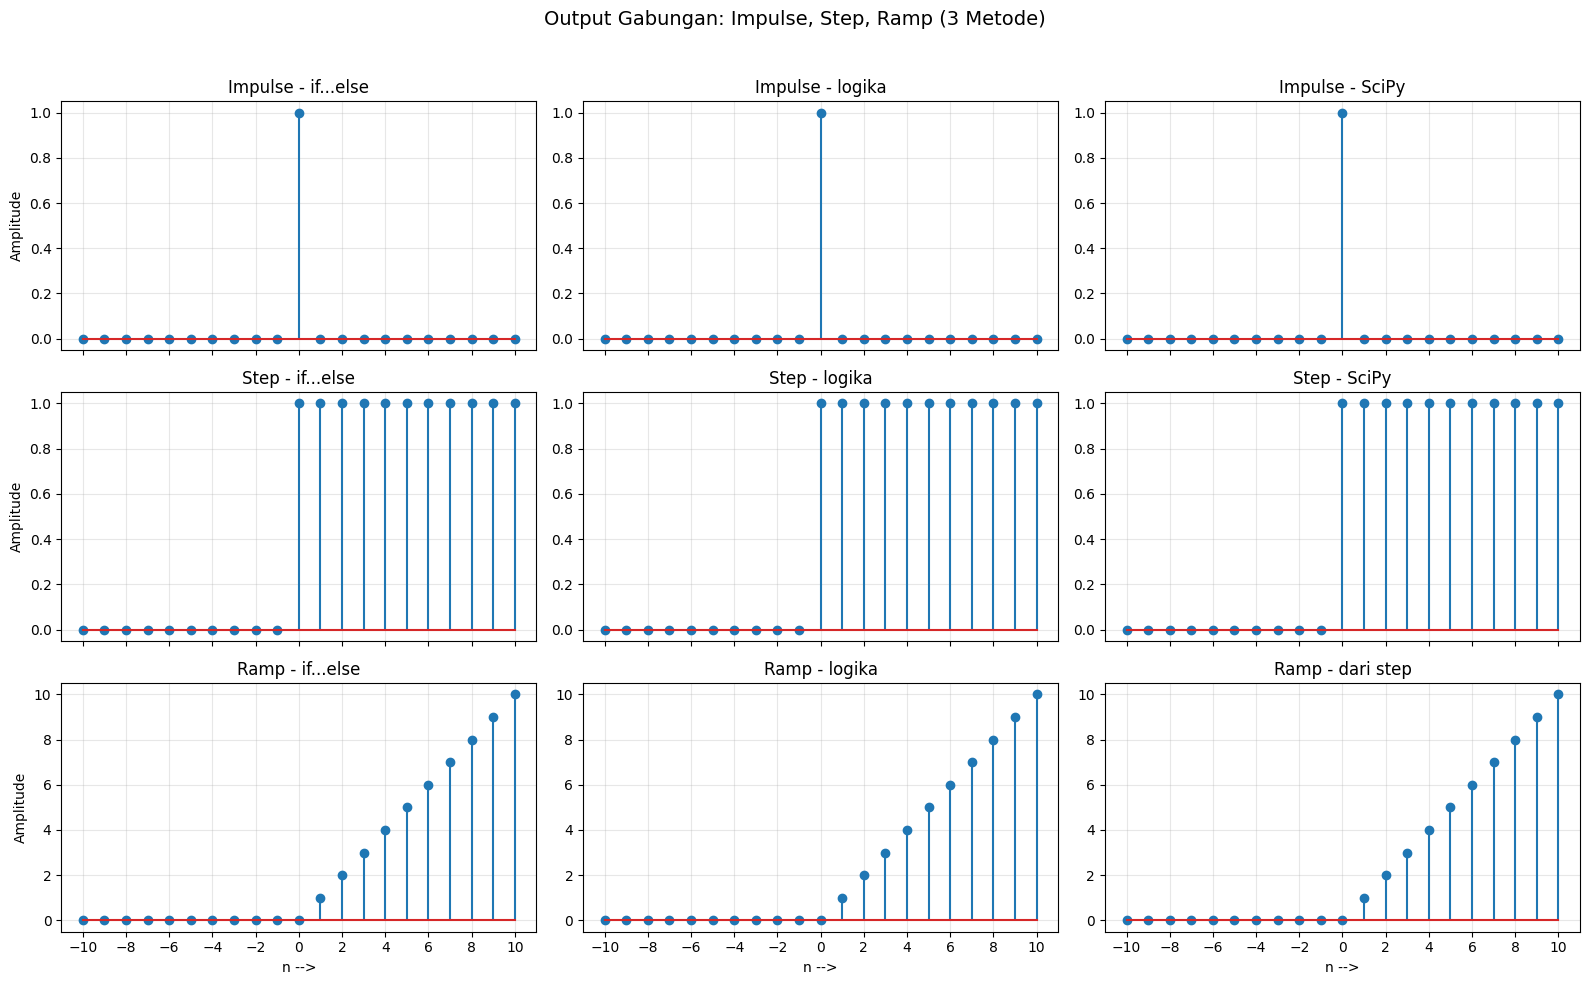

In [56]:
n = np.arange(-10, 11)
fig, axs = plt.subplots(3, 3, figsize=(16, 10), sharex=True)
fig.suptitle('Output Gabungan: Impulse, Step, Ramp (3 Metode)', fontsize=14)

# IMPULSE
x_if = np.array([1 if i == 0 else 0 for i in n])
x_logic = (n == 0).astype(int)
x_scipy = signal.unit_impulse(len(n), 'mid')

axs[0, 0].stem(n, x_if)
axs[0, 0].set_title('Impulse - if...else')
axs[0, 1].stem(n, x_logic)
axs[0, 1].set_title('Impulse - logika')
axs[0, 2].stem(n, x_scipy)
axs[0, 2].set_title('Impulse - SciPy')

# STEP
u_if = np.array([1 if i >= 0 else 0 for i in n])
u_logic = (n >= 0).astype(int)
imp = signal.unit_impulse(len(n), 'mid')
u_scipy = np.cumsum(imp)

axs[1, 0].stem(n, u_if)
axs[1, 0].set_title('Step - if...else')
axs[1, 1].stem(n, u_logic)
axs[1, 1].set_title('Step - logika')
axs[1, 2].stem(n, u_scipy)
axs[1, 2].set_title('Step - SciPy')

# RAMP
r_if = np.array([i if i >= 0 else 0 for i in n])
r_logic = n * (n >= 0)
r_scipy = np.cumsum(u_scipy) - u_scipy

axs[2, 0].stem(n, r_if)
axs[2, 0].set_title('Ramp - if...else')
axs[2, 1].stem(n, r_logic)
axs[2, 1].set_title('Ramp - logika')
axs[2, 2].stem(n, r_scipy)
axs[2, 2].set_title('Ramp - dari step')

for i in range(3):
    for j in range(3):
        axs[i, j].set_xticks(n[::2])
        axs[i, j].grid(alpha=0.3)
        if j == 0:
            axs[i, j].set_ylabel('Amplitude')
        if i == 2:
            axs[i, j].set_xlabel('n -->')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Keterangan Jurnal I (Impulse, Step, Ramp)
1. Ketiga metode pembangkitan sinyal (if...else, logika boolean, dan fungsi turunan SciPy) menghasilkan bentuk sinyal yang setara.
2. Sinyal impulse hanya bernilai 1 pada n = 0 dan 0 di indeks lain, sehingga cocok sebagai acuan awal pembentukan sinyal diskrit.
3. Sinyal step bernilai 0 untuk n < 0 dan 1 untuk n >= 0. Hasil dari metode cumsum impulse menunjukkan hubungan antara impulse dan step.
4. Sinyal ramp meningkat linier untuk n >= 0 dan 0 untuk n < 0. Ramp dapat dibentuk dari akumulasi step, sehingga terlihat keterkaitan antar sinyal dasar.
5. Dari ketiga kolom metode, perbedaan utama ada pada cara implementasi kode, bukan pada hasil sinyal akhirnya.

## JURNAL II
Gunakan nilai alpha = 2 dan alpha = -2 untuk sinyal eksponensial real.
Untuk sinyal eksponensial kompleks, gunakan rentang omega 0 sampai 2*pi dan -pi sampai pi.

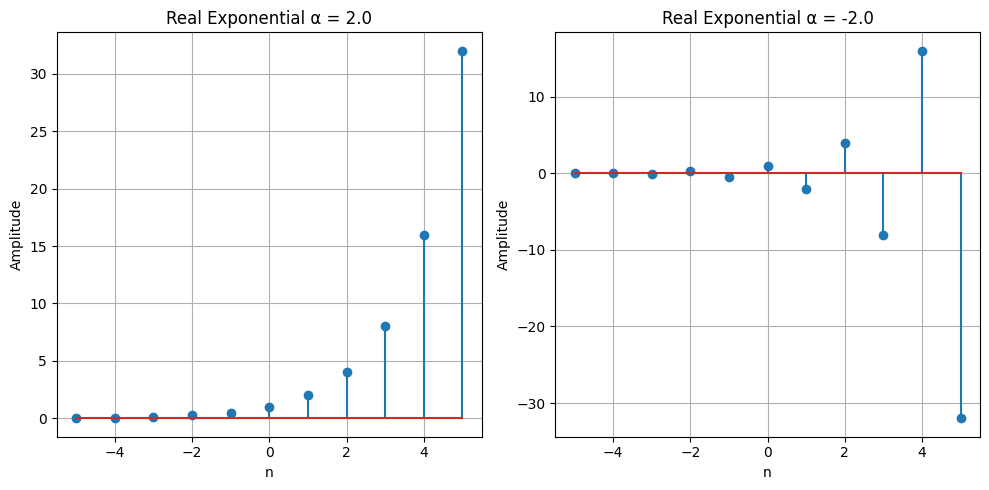

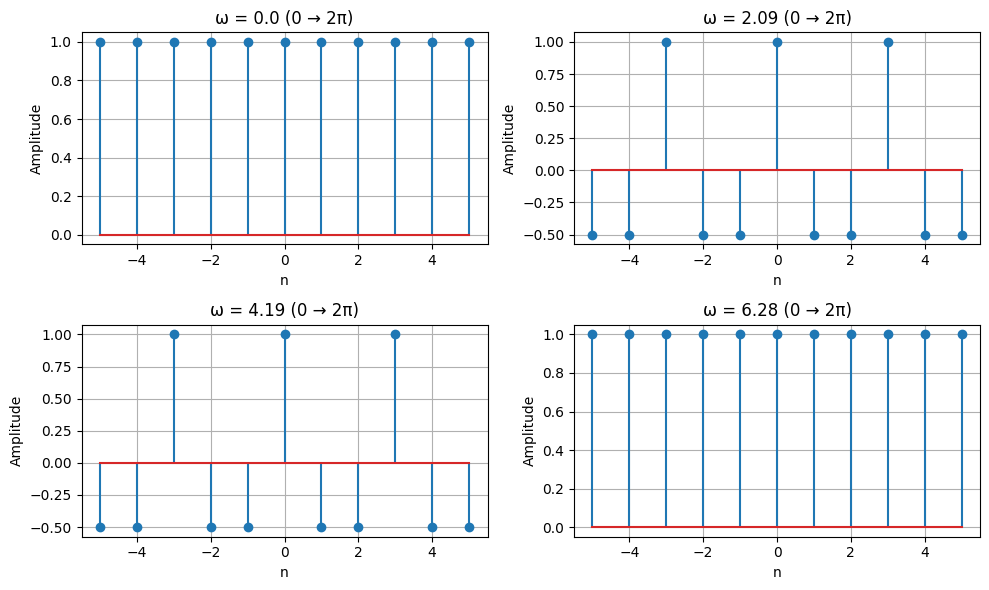

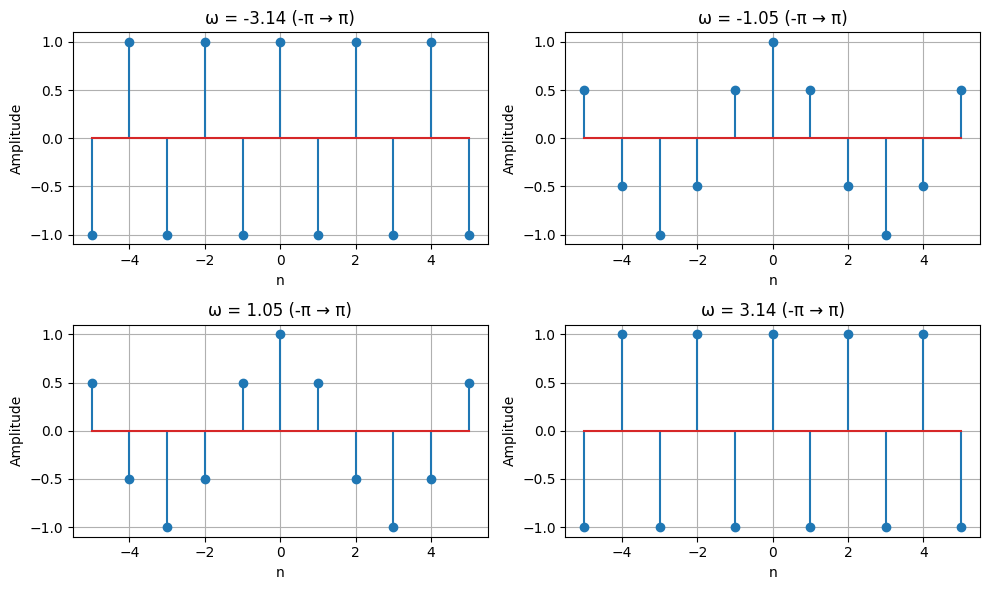

In [57]:
# Eksponensial real: alpha = 2 dan alpha = -2
# ==========================================
# 1. DOMAIN
# ==========================================
n = np.arange(-5, 6)

# ==========================================
# 2. REAL EXPONENTIAL (α = 2 dan -2)
# ==========================================

# PAKAI FLOAT BIAR AMAN
alpha = [2.0, -2.0]

plt.figure(figsize=(10,5))

for i in range(len(alpha)):
    x = alpha[i] ** n   # SEKARANG AMAN
    
    plt.subplot(1,2,i+1)
    plt.stem(n, x)
    plt.title(f'Real Exponential α = {alpha[i]}')
    plt.xlabel('n')
    plt.ylabel('Amplitude')
    plt.grid()

plt.tight_layout()
plt.show()

# ==========================================
# 3. COMPLEX EXPONENTIAL (0 → 2π)
# ==========================================

omega1 = np.linspace(0, 2*np.pi, 4)

plt.figure(figsize=(10,6))

for i in range(len(omega1)):
    x = np.exp(1j * omega1[i] * n)
    
    plt.subplot(2,2,i+1)
    plt.stem(n, np.real(x))  # ambil bagian real
    plt.title(f'ω = {round(omega1[i],2)} (0 → 2π)')
    plt.xlabel('n')
    plt.ylabel('Amplitude')
    plt.grid()

plt.tight_layout()
plt.show()

# ==========================================
# 4. COMPLEX EXPONENTIAL (-π → π)
# ==========================================

omega2 = np.linspace(-np.pi, np.pi, 4)

plt.figure(figsize=(10,6))

for i in range(len(omega2)):
    x = np.exp(1j * omega2[i] * n)
    
    plt.subplot(2,2,i+1)
    plt.stem(n, np.real(x))
    plt.title(f'ω = {round(omega2[i],2)} (-π → π)')
    plt.xlabel('n')
    plt.ylabel('Amplitude')
    plt.grid()

plt.tight_layout()
plt.show()

### Komentar Hasil Output
1. Untuk alpha = 2, amplitudo sinyal bertambah cepat saat n positif dan mengecil saat n negatif.
2. Untuk alpha = -2, amplitudo juga membesar mengikuti |2|^n, tetapi tanda sinyal berganti-ganti (+/-) setiap kenaikan n.
3. Untuk omega dengan rentang 0 sampai 2*pi dan -pi sampai pi, bentuk sinyal kompleks tetap periodik dan ekuivalen (hanya beda representasi sumbu omega), karena periodenya 2*pi.

## JURNAL III - Signal Signum
Definisi signum secara piecewise:
- sgn[n] = 1, untuk n > 0
- sgn[n] = 0, untuk n = 0
- sgn[n] = -1, untuk n < 0

Langkah pengerjaan (2 grafik):
1. Definisikan dulu sgn[n] berdasarkan kondisi piecewise.
2. Generate signum dari step dengan relasi sgn[n] = u[n] - u[-n], lalu bandingkan grafiknya.

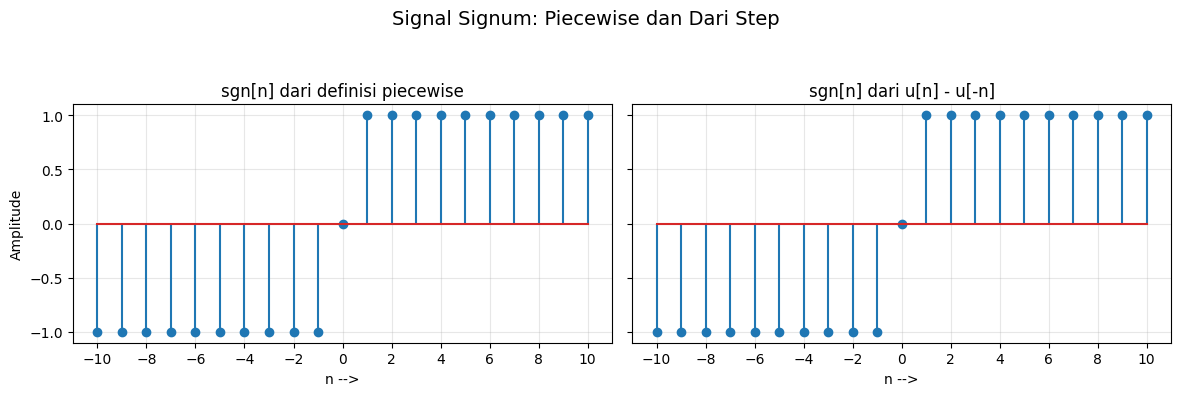

Piecewise == dari step ? True


In [58]:
n = np.arange(-10, 11)

# 1) Definisi piecewise
sgn_piecewise = np.array([1 if k > 0 else (0 if k == 0 else -1) for k in n])

# 2) Generate signum dari step: sgn[n] = u[n] - u[-n]
u_n = (n >= 0).astype(int)
u_neg_n = ((-n) >= 0).astype(int)
sgn_from_step = u_n - u_neg_n

fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
fig.suptitle('Signal Signum: Piecewise dan Dari Step', fontsize=14)

axs[0].stem(n, sgn_piecewise)
axs[0].set_title('sgn[n] dari definisi piecewise')
axs[0].set_xlabel('n -->')
axs[0].set_ylabel('Amplitude')
axs[0].set_xticks(n[::2])
axs[0].grid(alpha=0.3)

axs[1].stem(n, sgn_from_step)
axs[1].set_title('sgn[n] dari u[n] - u[-n]')
axs[1].set_xlabel('n -->')
axs[1].set_xticks(n[::2])
axs[1].grid(alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

print('Piecewise == dari step ?', np.array_equal(sgn_piecewise, sgn_from_step))

### Keterangan Jurnal III (Signal Signum)
1. Definisi piecewise menghasilkan nilai signum sesuai teori: -1 untuk n < 0, 0 untuk n = 0, dan 1 untuk n > 0.
2. Pembangkitan signum menggunakan relasi sgn[n] = u[n] - u[-n] menghasilkan grafik yang sama persis.
3. Nilai pemeriksaan `np.array_equal(...)` bernilai True, sehingga valid bahwa relasi step dapat digunakan sebagai bentuk alternatif pembangkitan signum.
4. Percobaan ini menegaskan bahwa satu sinyal diskrit dapat direpresentasikan dari kombinasi sinyal dasar lain.

## Kesimpulan Modul
1. Praktikum menunjukkan bahwa sinyal dasar diskrit (impulse, step, ramp, eksponensial, dan signum) dapat dibangkitkan dengan beberapa pendekatan yang berbeda namun menghasilkan bentuk yang konsisten.
2. Pada sinyal eksponensial real, parameter alpha menentukan pertumbuhan atau peredaman amplitudo serta perubahan tanda ketika alpha bernilai negatif.
3. Pada sinyal eksponensial kompleks, perubahan rentang omega hanya mengubah representasi frekuensi, sedangkan sifat periodiknya tetap mengikuti periode 2*pi.
4. Verifikasi signum dari definisi piecewise dan dari relasi step membuktikan kesetaraan matematis antar representasi sinyal.
5. Secara keseluruhan, hasil modul memperkuat pemahaman bahwa hubungan antar sinyal dasar sangat penting sebagai fondasi analisis sistem sinyal digital.